# Fig. A1: weathering at the background CO$_2$

In [1]:
from helpers import *

# WHAK parameter sets; baseline is West et al. (2005)
WHAK_PARAMS = {
    "baseline":   dict(mu=0.75, gamma=0.095, beta=0.0),
    "mu_high":    dict(mu=1.00, gamma=0.095, beta=0.0),  # Dessert et al. 2003
    "mu_zero":    dict(mu=0.0,  gamma=0.095, beta=0.0),  # temperature only
    "gamma_high": dict(mu=0.75, gamma=0.150, beta=0.0),  # West et al. 2005
    "gamma_zero": dict(mu=0.75, gamma=0.0,   beta=0.0),  # runoff only
    "beta_low":   dict(mu=0.75, gamma=0.095, beta=0.3),
}

# weathering grids for each WHAK parameter set and for MAC
results = {name: load_grid("default", "0Ma", **p) for name, p in WHAK_PARAMS.items()}
mac_grid = load_grid("default", "0Ma", law="mac")

# background temperature: global mean T of the reference run (0 Ma, no OHT, 1361 W/m2, 280 ppm)
REF_T = reference_T("default")
ages = load_ages("default", "0Ma")

def wsum_at_background(grid):
    # (time, normalized weathering) at the background CO2 for each simulated solar constant
    out = []
    for g in sorted(grid):
        cb = background_co2_via_temperature(grid, g, T_target=REF_T)
        out.append((ages[g], wsum_at_co2(grid, g, cb)))
    return out

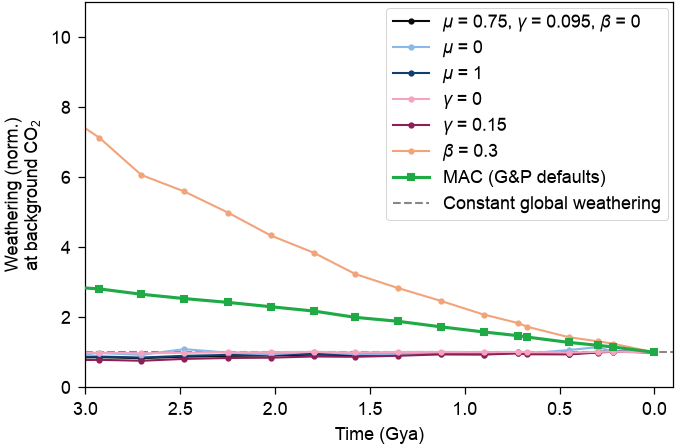

In [2]:
# colors by parameter: blue for mu, pink for gamma, orange for beta, light to dark for low to high
PARAM_COLORS = {"baseline": "#0b0b0b", "mu_zero": "#8ab8e8", "mu_high": "#11406f",
                "gamma_zero": "#f5a3c0", "gamma_high": "#8c1f55", "beta_low": "#f2a37a"}
MAC_COLOR = "#1faa46"
GREY = "#898781"
PARAM_LABELS = {"baseline": r"$\mu$ = 0.75, $\gamma$ = 0.095, $\beta$ = 0", "mu_zero": r"$\mu$ = 0", "mu_high": r"$\mu$ = 1",
                "gamma_zero": r"$\gamma$ = 0", "gamma_high": r"$\gamma$ = 0.15", "beta_low": r"$\beta$ = 0.3"}

fig, ax = plt.subplots(figsize=(MEDIUM_WIDTH, MEDIUM_HEIGHT))
lines = {}
for name in WHAK_PARAMS:
    lines[name], = ax.plot(*zip(*wsum_at_background(results[name])), marker="o", ms=2, color=PARAM_COLORS[name],
                           label=PARAM_LABELS[name])
lines["MAC"], = ax.plot(*zip(*wsum_at_background(mac_grid)), marker="s", ms=2.5, lw=1.5, color=MAC_COLOR,
                        label="MAC (G&P defaults)", zorder=5)
lines["constant"] = ax.axhline(1.0, color=GREY, ls="--", zorder=0, label="Constant global weathering")
ax.set_ylim(0, 11)
setup_time_ax(ax)
ax.set_ylabel("Weathering (norm.)\nat background CO$_2$")
order = ["baseline", "mu_zero", "mu_high", "gamma_zero", "gamma_high", "beta_low", "MAC", "constant"]
ax.legend(handles=[lines[k] for k in order], loc="upper right")
plt.tight_layout()
fig.savefig("figs/wsum_at_background.pdf", bbox_inches="tight")
plt.show()

In [3]:
# weathering at 3 Ga, and its range since 3 Ga, relative to the modern reference run
for name, grid in list(results.items()) + [("MAC", mac_grid)]:
    t, w = np.array(wsum_at_background(grid)).T
    print(f"{name:11s} {np.interp(3.0, t[::-1], w[::-1]):.2f} at 3 Ga, {w[t <= 3].min():.2f}-{w[t <= 3].max():.2f} since 3 Ga")

baseline    0.85 at 3 Ga, 0.83-1.02 since 3 Ga
mu_high     0.88 at 3 Ga, 0.85-1.03 since 3 Ga
mu_zero     0.94 at 3 Ga, 0.93-1.15 since 3 Ga
gamma_high  0.78 at 3 Ga, 0.76-1.02 since 3 Ga
gamma_zero  0.99 at 3 Ga, 0.97-1.02 since 3 Ga
beta_low    7.40 at 3 Ga, 1.00-7.13 since 3 Ga
MAC         2.84 at 3 Ga, 1.00-2.81 since 3 Ga
